# Verne, small, step 06: DAgger, explained

Results: `06_dagger.ipynb`. Seed 0 policies, T1-wide.

`dream_robot/policies/verne/dagger.py`, rebuilt one piece at a time. At every step of a DAgger episode:

```-
observation ──► StateExpert ──► label   ──► saved in the dataset
            └─► Verne policy ──► action ──► sent to env.step
```

The policy picks where the robot goes; the expert says what it would do there.

In [1]:
%load_ext autoreload
%autoreload 2

### step 1 — what one round recorded

Round 1 (`dagger_r1`): step 05's policy drove 100 episodes.

In [2]:
import json

from dream_robot.policies.verne.data import REPO

summary = json.loads((REPO / 'data/robosuite/dagger_r1/recording_summary.json').read_text())
{k: v for k, v in summary.items() if k != 'episodes'}

{'repo_id': 'dream_robot/pick_place_cube',
 'root': '/home/rahul/Documents/codes/ml/dream-robot/data/robosuite/dagger_r1',
 'task_prompt': 'put the cube in the bin',
 'perturbation': {'type': 'dagger',
  'policy': '05_square/t1-wide-square-noise/seed0'},
 'attempted': 100,
 'kept': 100,
 'total_frames': 33062,
 'expert_success_rate': 0.79,
 'failure_histogram': {'dropped': 7, 'no_grasp': 14}}

**100 attempted, 100 kept: failures stay in the dataset.**
- 79 placed, 21 failed (14 `no_grasp`, 7 `dropped`); 33,062 frames.
- `expert_success_rate` is the recorder's name; here it's the *policy's* success, since the policy drove.
- `perturbation` names the driving policy: that's `RunPolicy.to_dict()`.

### step 2 — the policy's normalisation stats

From the task the driving policy was trained on: the same numbers it saw in training.

In [3]:
from types import SimpleNamespace

import numpy as np
import torch

from dream_robot.policies.verne.run import load_task

state, action, episode, _, train_ids, _, wide = load_task('t1-wide-square-noise')
lab = np.isin(episode, train_ids)
d = SimpleNamespace(
    s_mean=torch.tensor(state[lab].mean(0), device='cuda'),
    s_std=torch.tensor(state[lab].std(0, ddof=1), device='cuda'),
    a_mean=torch.tensor(action[lab].mean(0), device='cuda'),
    a_std=torch.tensor(action[lab].std(0, ddof=1), device='cuda'),
)
state.shape, lab.sum(), wide

((25726, 8), np.int64(23157), True)

**25,726 rows; 23,157 are training rows** (the 90 training demos; the 10 held-out ones are left out of the stats).

### step 3 — the driver, the labeller, the scene

In [4]:
from dream_robot.policies.verne import rollouts, vae
from dream_robot.policies.verne.run import RUNS
from dream_robot.sims.robosuite.tasks.pick_place_cube.expert import StateExpert

net = rollouts.load(torch.load(RUNS / '05_square/t1-wide-square-noise/seed0/weights.pt'))
enc = vae.load(vae.WEIGHTS)
env = rollouts.make_env(wide)
expert = StateExpert(env, square_up=True)

### step 4 — one step: the label and the policy's action, same observation

8 numbers each: 7 joint targets + gripper (1 open, 0 closed).

In [5]:
np.set_printoptions(precision=3, suppress=True)
obs = env.reset(seed=2000)
expert.reset()
torch.manual_seed(2000 * 100 + 8)  # as DaggerActor.reset does
label = expert(obs)
chunk = rollouts.act(net, enc, d, obs)
print('joints now', obs.state[:7])
print('label     ', label)
print('policy    ', chunk[0], ' chunk', chunk.shape)

joints now [-0.023  0.166 -0.015 -2.617 -0.029  2.951  0.781]
label      [-0.009  0.226 -0.075 -2.557 -0.031  3.011  0.841  1.   ]
policy     [-0.008  0.229 -0.103 -2.55   0.003  3.009  0.862  0.985]  chunk (16, 8)


**At the start they agree:** both head off the home pose the same way, joints within ~0.03 rad.
- The label is one action; the policy returns a 16-step chunk, and DAgger runs the first 8 before it asks again.
- Both have gripper ≈ 1, open. The labels earn their keep later, in states where the policy has drifted off the demos.

### step 5 — a whole episode by hand

Seed 2004: in round 1 the policy never grasped (`no_grasp`, ran all 600 steps). Every step: the expert labels, the policy's plan runs (replanned every 8).

In [9]:
seed = 2004
obs = env.reset(seed=seed)
expert.reset()
torch.manual_seed(seed * 100 + 8)
labels, executed, phases, plan = [], [], [], []
cube_z, opening = [], []  # what the scene did
while True:
    labels.append(expert(obs))
    phases.append(expert.phase)
    cube_z.append(env.cube_pos[2])
    opening.append(obs.state[-1])
    if not plan:
        plan = list(rollouts.act(net, enc, d, obs)[:8])
    executed.append(plan.pop(0))
    r = env.step(executed[-1])
    obs = r.observation
    if r.terminated or r.truncated:
        break
labels, executed = np.array(labels), np.array(executed)
len(labels), r.success, r.failure_mode

(600, False, <FailureMode.NO_GRASP: 'no_grasp'>)

**Same as round 1: 600 steps, `no_grasp`.** Same seed and the same torch seed replay the recorded episode.

Top: how far the label is from what ran (joint distance). Bottom: the gripper, label vs executed. Shading: the expert's phase.

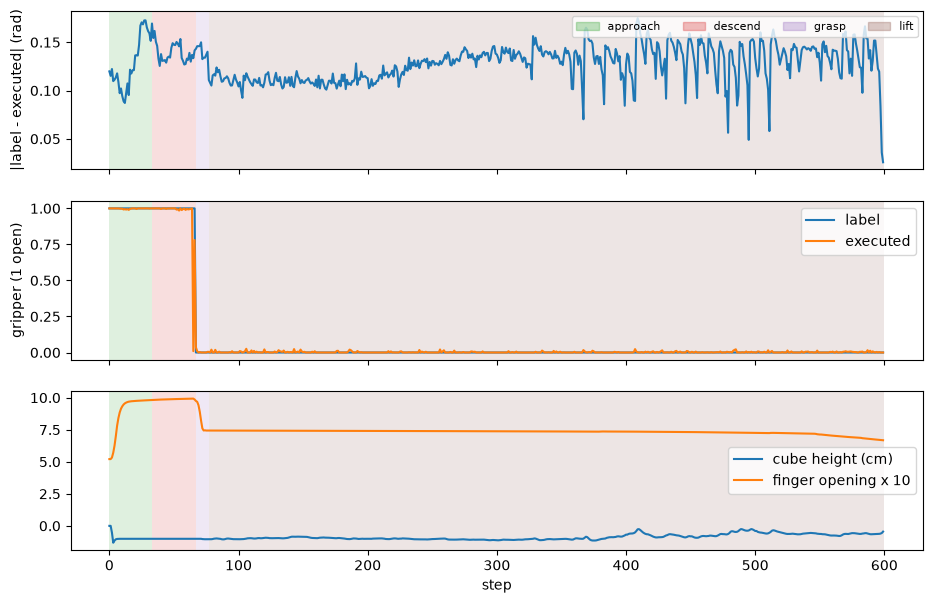

In [10]:
import matplotlib.pyplot as plt

fig, (a, b, s) = plt.subplots(3, 1, figsize=(11, 7), sharex=True)
a.plot(np.linalg.norm(labels[:, :7] - executed[:, :7], axis=1))
a.set_ylabel('|label - executed| (rad)')
b.plot(labels[:, 7], label='label')
b.plot(executed[:, 7], label='executed')
b.set_ylabel('gripper (1 open)')
b.legend()
s.plot(100 * (np.array(cube_z) - cube_z[0]), label='cube height (cm)')
s.plot(10 * np.array(opening), label='finger opening x 10')
s.set_xlabel('step')
s.legend()
names = sorted(set(phases))
for t, ph in enumerate(phases):
    for ax in (a, b, s):
        ax.axvspan(t, t + 1, color=f'C{names.index(ph) + 2}', alpha=0.15, lw=0)
a.legend(
    handles=[plt.Rectangle((0, 0), 1, 1, color=f'C{i + 2}', alpha=0.3) for i in range(len(names))],
    labels=names,
    ncol=len(names),
    loc='upper right',
    fontsize=8,
)
plt.show()

**Seed 2004 is a hold that never lifts.**
- Step ~65: the policy closes and the fingers stop at 0.75 open: they're on the cube (a square grip is ~0.5, so probably diagonal).
- From there the expert says `lift` for 520 steps: cube between the fingers, opening in the held band (0.25-0.85).
- The policy never lifts. The cube stays on the table (the 1 cm drop at the start is the cube settling after reset).
- The label stays ~0.1-0.15 rad from what ran the whole time. These 520 lift labels in a state no demo shows are what the next policy trains on.
- Why it counts as `no_grasp`: the env only calls it a grasp once the cube is lifted.

### step 6 — the same loop, as dagger.py's two classes

The recorder's loop (`core/record.py` `rollout`), per step:

```-
action = policy(obs)                  # saved
env.step(perturb(action, rng))        # run
```

- `DaggerActor` is the `policy`: returns the expert's label, and stashes the policy's next planned action in `.executed`.
- `RunPolicy` is the `perturb`: ignores the label, returns `actor.executed`.

In [11]:
from dream_robot.policies.verne.dagger import DaggerActor, RunPolicy

actor = DaggerActor(expert, net, enc, d, seed_start=seed)
hook = RunPolicy(actor, '05_square/t1-wide-square-noise/seed0')
hook.to_dict()

{'type': 'dagger', 'policy': '05_square/t1-wide-square-noise/seed0'}

One episode through the recorder's own `rollout` (in memory; `record_episodes` would loop this and write the dataset).

In [12]:
from dream_robot.core.record import rollout

ep = rollout(env, actor, seed=seed, perturb=hook)
ep.actions.shape, ep.success, ep.failure_mode

((600, 8), False, <FailureMode.NO_GRASP: 'no_grasp'>)

The saved actions vs step 5's labels, by hand:

In [13]:
np.abs(ep.actions - labels).max()

np.float32(0.0)

And against what round 1 saved on disk (seed 2004 = episode 4):

In [14]:
from dream_robot.policies.verne.data import load_table

_, r1_action, r1_episode = load_table('dagger_r1')
np.abs(r1_action[r1_episode == 4] - ep.actions).max()

np.float32(0.0)

**All three agree to the bit (max difference 0.0):** step 5's loop by hand, the recorder with `DaggerActor` + `RunPolicy`, and round 1's dataset on disk.
- So `dagger.py` is just step 5's loop split across the recorder's two hooks.
- `collect()` adds the rest: the stats (step 2), the loaded pieces (step 3), `keep_failures=True`, and `tracking_tolerance=inf`. The recorder normally checks that the saved action matches where the arm went next; here it ran the policy's action, so it doesn't.

### step 7 — training on the failures only

`run.py` `load_task('base+round:fail')`: the base demos, plus only the round's failed episodes, renumbered `1000·k + i` (k = 1 for the first extra) so they can't clash with base episode ids.

In [15]:
state, action, episode, _, train_ids, val_ids, _ = load_task('t1-wide-square-noise+dagger_r1:fail')
extra = np.unique(episode[episode >= 1000])
len(state), len(train_ids), len(val_ids), extra[:6]

(38326, 111, 10, array([1004, 1005, 1011, 1013, 1018, 1021]))

The kept episodes vs the round's failures in its `recording_summary.json` (step 1):

In [16]:
failed = [i for i, e in enumerate(summary['episodes']) if not e['success']]
list(extra - 1000) == failed, len(failed)

(True, 21)

**21 failed episodes added, nothing else.**
- Rows 25,726 → 38,326: + 21 × 600. Every failure ran to the 600-step limit, so a failure brings far more frames than a success would (~330).
- Training episodes 90 → 111. Validation stays the base's 10 held-out demos, so val loss compares with the base run's.
- Episode 1004 = round 1's episode 4 = seed 2004, the hold that never lifts (step 5).
- Round 2 stacks the same way: `base+dagger_r1:fail+dagger_r2:fail`, its episodes at 2000 + i.

### wrap-up

```-
collect (dagger.py)                          train (run.py load_task)
policy k drives, StateExpert labels          base demos
every episode kept, failures included   ─►   + round k's failed episodes only
data/robosuite/dagger_rk                     val = base's held-out 10
```

- One DAgger step is step 5's loop; `dagger.py` splits it over the recorder's hooks (step 6, identical to the saved data).
- What the labels add: actions in states no demo has, e.g. 520 `lift` labels on a hold the policy never lifts.
- Results (`06_dagger.ipynb`, seed 0, n_exec 8 / 16): base 42 / 44 → + r1 failed 45 / 47 → + r2 failed 48 / 47.